In [2]:
import numpy as np
from optiland import optic

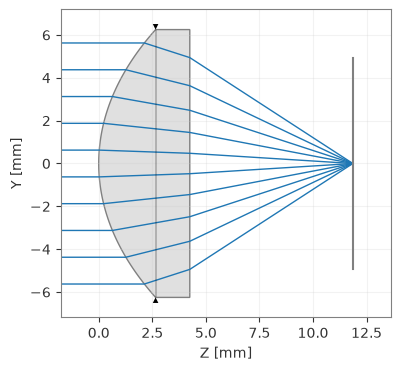

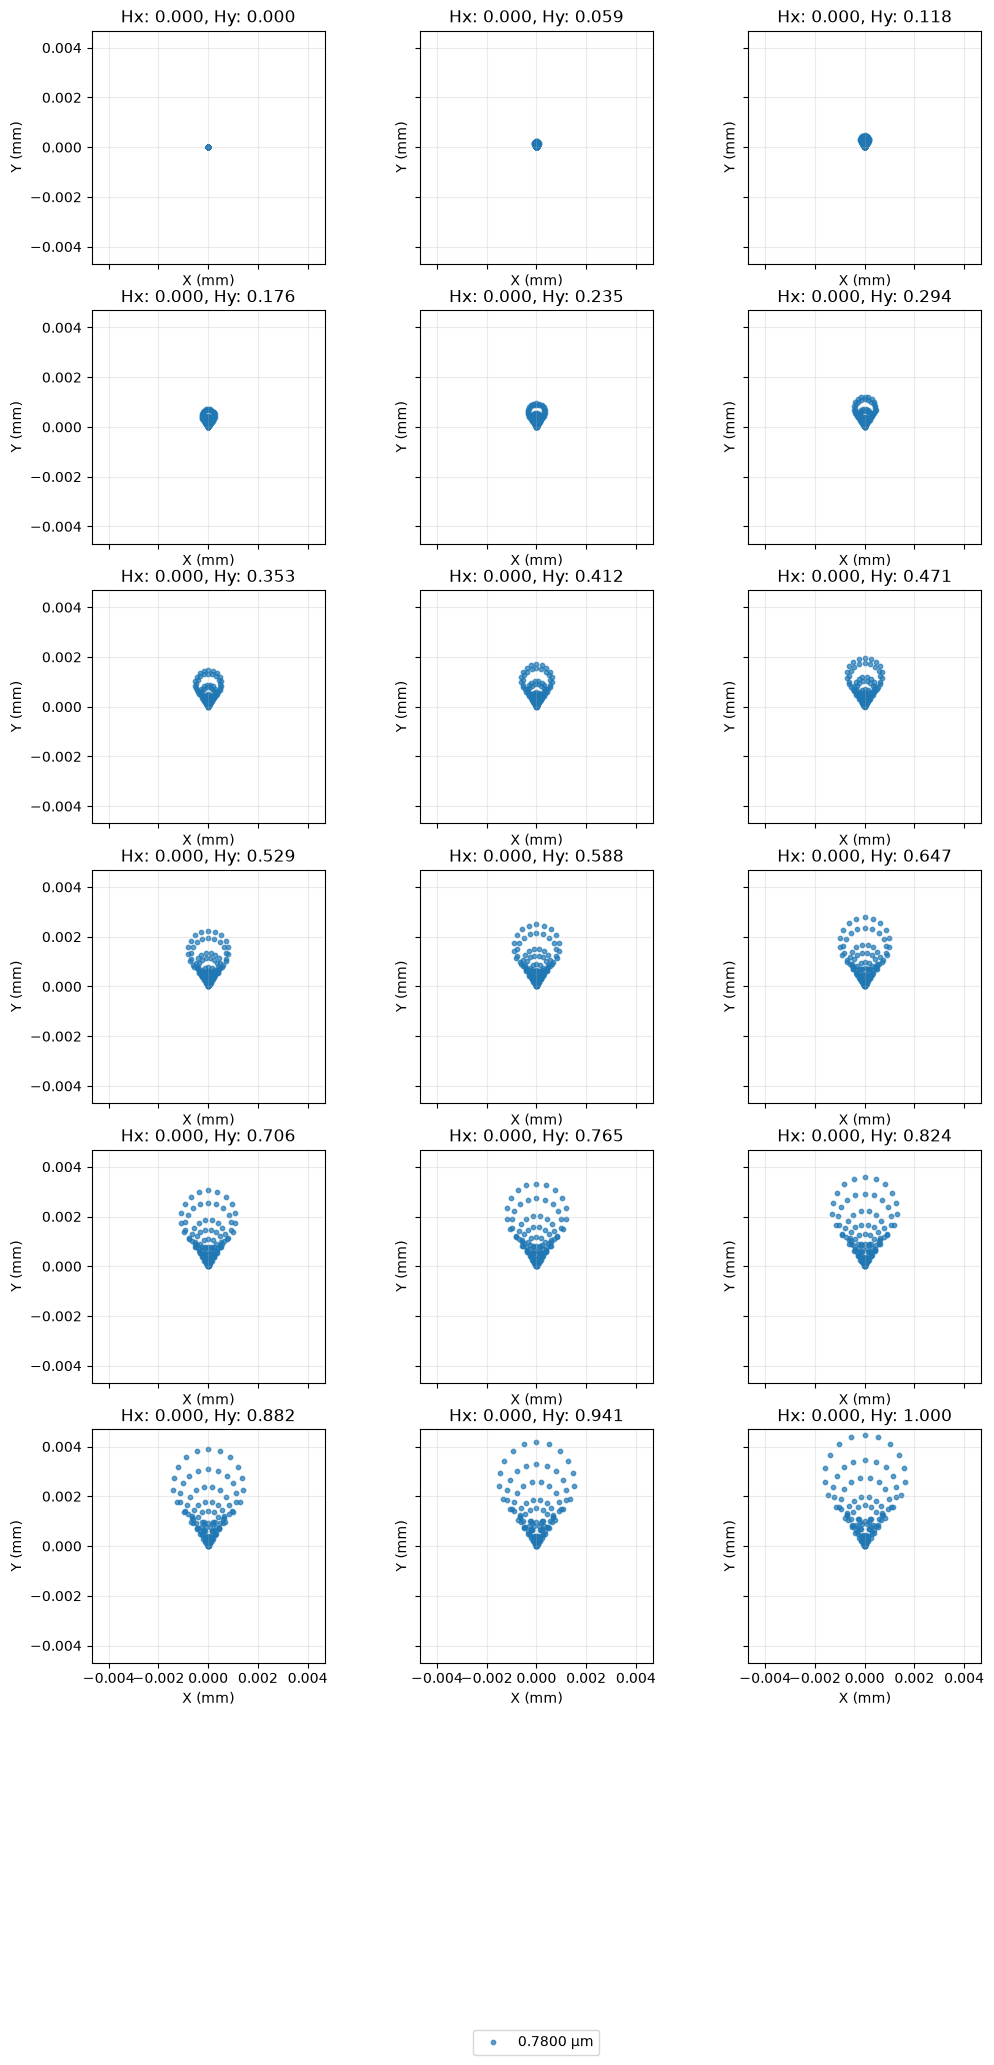

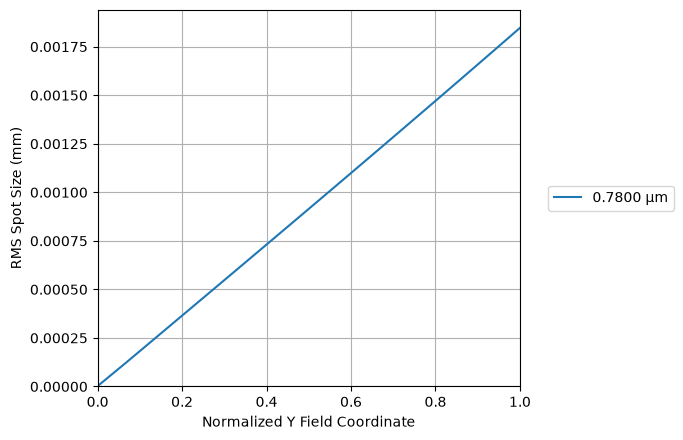

Optimized RMS spot radius by field (um):
[[np.float64(1.9709297415269128e-06)], [np.float64(0.00010729861316896602)], [np.float64(0.00021459822915099937)], [np.float64(0.0003219601834736384)], [np.float64(0.00042940807302992336)], [np.float64(0.0005369690788340277)], [np.float64(0.0006446709375056326)], [np.float64(0.0007525414984426452)], [np.float64(0.0008606086043732612)], [np.float64(0.0009689000438725844)], [np.float64(0.0010774435255873425)], [np.float64(0.0011862666604603113)], [np.float64(0.0012953969474162224)], [np.float64(0.001404861760759601)], [np.float64(0.0015146883385455953)], [np.float64(0.0016249037716022502)], [np.float64(0.0017355349930288486)], [np.float64(0.0018466087681034277)]]
Maximum ray radius by field (um):
[[np.float64(3.390102832290859e-06)], [np.float64(0.00023818874546611274)], [np.float64(0.00047642367941384475)], [np.float64(0.0007180969525157187)], [np.float64(0.0009632106252020385)], [np.float64(0.0012117667705664817)], [np.float64(0.0014637674744042

In [11]:
from optiland.fileio import load_optiland_file, save_optiland_file
from optiland.fileio import load_zemax_file
from optiland.prescription import Prescription
from optiland.analysis import RayFan, RmsSpotSizeVsField, SpotDiagram
from optiland.diagnostics import check_system
from optiland.optic import Optic
from optiland.solves import QuickFocusSolve
from optiland.optimization import OptimizationProblem, OptimizerGeneric

AL1210 = load_zemax_file("C:/Users/saten/Downloads/AL1210-Zemax-ZMX.zmx")
AL1210.draw(num_rays=10)

AL1210.set_aperture(aperture_type="EPD", value=8)

field_separation = (180 / np.pi) * (1e-3 / 10)
num_fields = 17
M = 5
field_separation *= M
for i in range(num_fields):
    AL1210.fields.add(y=(i+1)*field_separation)

focusing = QuickFocusSolve(AL1210)
focusing.apply()

spot = SpotDiagram(AL1210, num_rings = 6, fields = "all")
spot.view()
#RayFan(AL1210).view()
RmsSpotSizeVsField(AL1210, num_fields = 16).view()

print("Optimized RMS spot radius by field (um):")
print(spot.rms_spot_radius())
print("Maximum ray radius by field (um):")
print(spot.geometric_spot_radius())
print("Centroid by field (um):")
print(spot.centroid())

In [12]:
AL1210.wavelengths.remove(index = 0)
AL1210.wavelengths.add(value = 1.55)
#filed_separation = 1/17
#num_fields = 5
#for i in range(num_fields):
#    AL1210.fields.add(y=(i+1)*filed_separation)
#focusing = QuickFocusSolve(AL1210)
#focusing.apply()

In [13]:
problem = OptimizationProblem()

problem.add_variable(AL1210, "thickness", surface_number=2)

problem.add_operand(
    "rms_spot_size",
    target=0.0,
    weight=1.0,
    input_data={
        "optic": AL1210,
        "Hx": 0.0,
        "Hy": 0.0,
        "num_rings": 6,
        "wavelength": 1.55,
        "surface_number": -1,  # the image surface
    },
)

print(f"Merit function before: {float(problem.sum_squared()):.6f}")
OptimizerGeneric(problem).optimize(maxiter=200)
print(f"Merit function after: {float(problem.sum_squared()):.6f}")

Merit function before: 0.003768


c:\Users\saten\Documents\Umberto\Repositories\OpticalEngineering\.venv\Lib\site-packages\optiland\optimization\optimizer\scipy\base.py:110: OptimizeWarning: Unknown solver options: disp
  result = optimize.minimize(


Merit function after: 0.000001


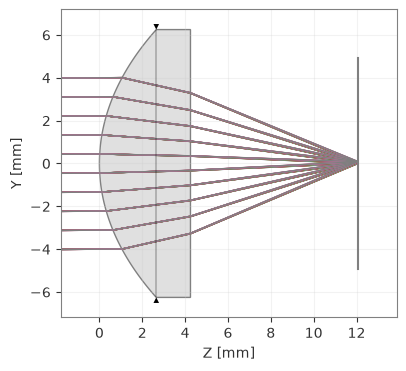

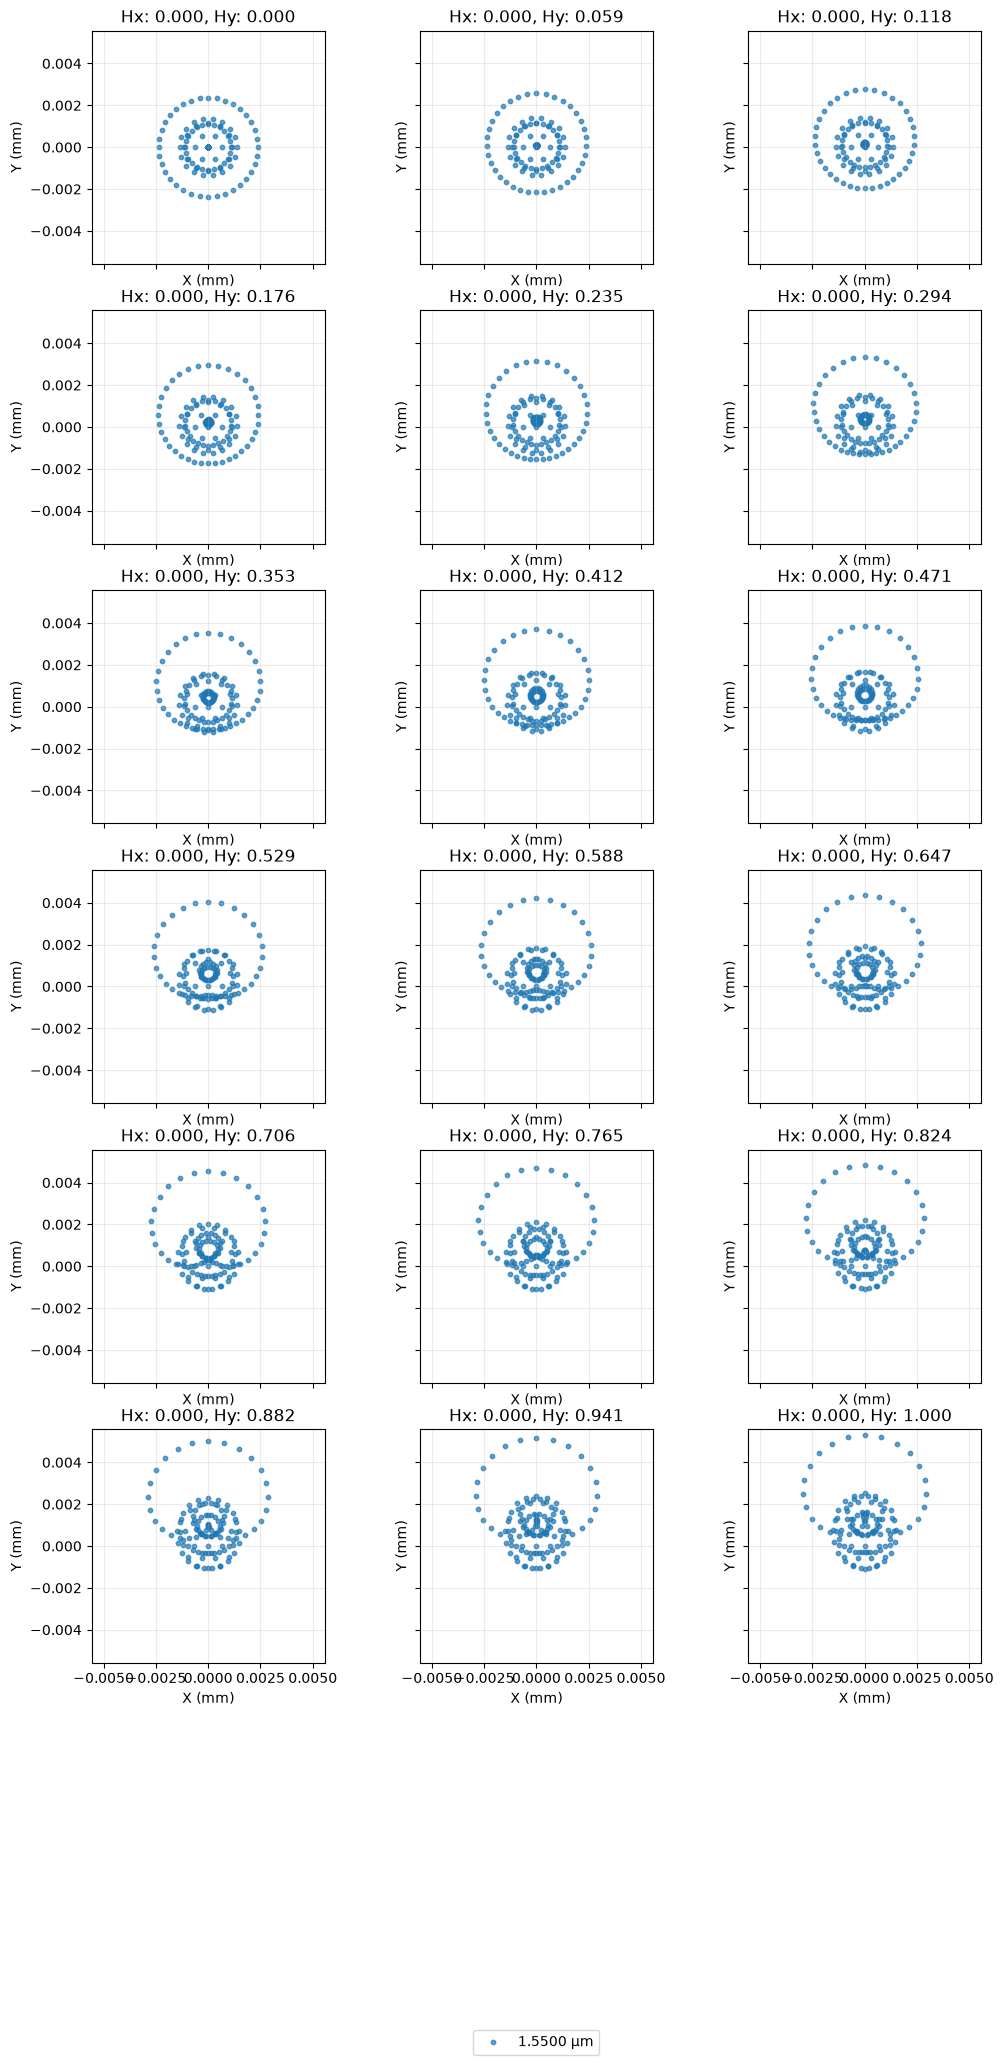

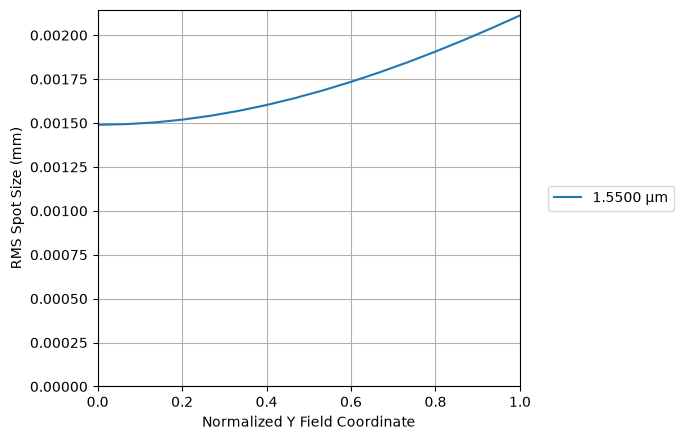

Optimized RMS spot radius by field (um):
[[np.float64(0.0014902143678115973)], [np.float64(0.0014927171252977689)], [np.float64(0.0015002043611147822)], [np.float64(0.0015126140052289716)], [np.float64(0.0015298459599325106)], [np.float64(0.0015517667513900856)], [np.float64(0.001578215359978582)], [np.float64(0.0016090096951560451)], [np.float64(0.0016439531937606625)], [np.float64(0.00168284109767055)], [np.float64(0.0017254660818272437)], [np.float64(0.0017716230300144143)], [np.float64(0.0018211128722352638)], [np.float64(0.0018737454909545231)], [np.float64(0.0019293417689942548)], [np.float64(0.001987734890589069)], [np.float64(0.0020487710237209397)], [np.float64(0.002112309512341123)]]
Maximum ray radius by field (um):
[[np.float64(0.00236716306969599)], [np.float64(0.0025673796042128133)], [np.float64(0.002764167068540777)], [np.float64(0.0029575273318444076)], [np.float64(0.00314746225097938)], [np.float64(0.0033339736705029835)], [np.float64(0.003517063422710992)], [np.float

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Optical Prescription — Aspheric Lens, Ø12.5mm, EFL = 10.0mm, NA=0.545                                           │
╰──────────────────────────────────────── Generated: 2026-11-11 10:21 UTC ────────────────────────────────────────╯

───────────────────────────────────────────────── System Overview ─────────────────────────────────────────────────

 Name              Aspheric Lens, Ø12.5mm, EFL = 10.0mm, NA=0.545  
  Surfaces          2                                               
  Stop Surface      1.0000                                          
  Aperture Type     EPDAperture                                     
  Aperture Value    8.0000                                          
  Object Distance   ∞                                               
  Image Distance    7.8202                                         

 Wavelengths

 #   Wavelength (µm)   Primary  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  1   1.5500            ✓

... (7 outputs left out)

 S#   Material   nd       Vd        Semi-Diameter (mm)   Coating  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  0    Air        1.0000   —         —                    —        
  1    S-LAH64    1.7880   47.3685   —                    —        
  2    Air        1.0000   —         —                    —        
  3    Air        1.0000   —         —                    —       

───────────────────────────────────────── Seidel Aberration Coefficients ──────────────────────────────────────────

 S#      SI (Sph)    SII (Coma)   SIII (Astig)   SIV (Petz)   SV (Dist)   CL (LCA)   CT (TCA)  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  1       0.280808    -0.002211    -0.000037      -0.000064    -0.000002   N/A        N/A       
  2       -0.123856   0.002691     -0.000058      0.000000     0.000001    N/A        N/A       
  Total   0.156952    0.000480     -0.000095      -0.000064    -0.000000   N/A        N/A

7.8202146750808215


In [14]:
AL1210.draw(num_rays=10)
spot = SpotDiagram(AL1210, num_rings = 6, fields = "all")
spot.view()
#RayFan(AL1210).view()
RmsSpotSizeVsField(AL1210, num_fields = 16).view()

print("Optimized RMS spot radius by field (um):")
print(spot.rms_spot_radius())
print("Maximum ray radius by field (um):")
print(spot.geometric_spot_radius())
print("Centroid by field (um):")
print(spot.centroid())

p = Prescription(AL1210)
p.view()
print(AL1210.surfaces[2].thickness)

In [15]:
from optiland.coordinate_system import CoordinateSystem

class RigidLensPerturbation:
    """Move a group of surfaces as one rigid body.

    mode: 'tilt_x' / 'tilt_y' (radians, about `pivot`) or 'dx' / 'dy' / 'dz' (lens units).
    pivot: global (x, y, z) point to rotate about; default = vertex of the first surface.
    """

    def __init__(self, optic, surfaces, mode, sampler, pivot=None):
        self.optic, self.surfaces, self.mode, self.sampler = optic, list(surfaces), mode, sampler
        S = optic.surface_group.surfaces
        self._cs = [S[i].geometry.cs for i in self.surfaces]
        for cs in self._cs:
            if cs.reference_cs is not None:
                raise NotImplementedError("Surface uses a reference_cs; pivot math assumes global coordinates.")
        self._nominal = [tuple(float(v) for v in (cs.x, cs.y, cs.z, cs.rx, cs.ry)) for cs in self._cs]
        self.pivot = np.asarray(pivot if pivot is not None else self._nominal[0][:3], dtype=float)
        self.variable = f"rigid {mode}, surfaces {self.surfaces}"   # used as the label in results
        self.value = None

    def apply(self):
        self.value = float(self.sampler.sample())
        self._set(self.value)

    def reset(self):
        self._set(0.0)

    def _set(self, v):
        tx = v if self.mode == "tilt_x" else 0.0
        ty = v if self.mode == "tilt_y" else 0.0
        shift = np.zeros(3)
        if self.mode in ("dx", "dy", "dz"):
            shift["xyz".index(self.mode[1])] = v
        # Use Optiland's own rotation matrix so the sign convention matches its ray tracing
        R = np.asarray(CoordinateSystem(rx=tx, ry=ty).get_rotation_matrix(), dtype=float)
        for cs, (x, y, z, rx, ry) in zip(self._cs, self._nominal):
            cs.x, cs.y, cs.z = self.pivot + R @ (np.array([x, y, z]) - self.pivot) + shift
            cs.rx, cs.ry = rx + tx, ry + ty


In [16]:
from optiland.tolerancing import RangeSampler, SensitivityAnalysis, Tolerancing

tolerancing = Tolerancing(AL1210)

sampler = RangeSampler(start=AL1210.surfaces[2].thickness-0.05, end=AL1210.surfaces[2].thickness+0.05, steps=200)
tolerancing.add_perturbation("thickness", sampler, surface_number=2)

sampler = RangeSampler(start=-0.05, end=0.05, steps=200)
rigid = RigidLensPerturbation(AL1210, [1, 2], "dy", sampler)
tolerancing.perturbations.append(rigid)

sampler = RangeSampler(start=-0.051, end=0.051, steps=200)
pivot = 0
rigid = RigidLensPerturbation(AL1210, [1, 2], "tilt_y", sampler, pivot)
tolerancing.perturbations.append(rigid)

sampler = RangeSampler(start=-0.051, end=0.051, steps=200)
pivot = 6
rigid = RigidLensPerturbation(AL1210, [1, 2, 3], "tilt_y", sampler, pivot)
tolerancing.perturbations.append(rigid)


input_data = {"optic": AL1210}
tolerancing.add_operand("f2", input_data)

input_data = {
    "optic": AL1210,
    "surface_number": -1,
    "Hx": 0,
    "Hy": 0.0,
    "wavelength": 1.55,
    "num_rays": 10,
}  # surface_number=-1 means the last surface
tolerancing.add_operand("rms_spot_size", input_data, target=0)

input_data = {
    "optic": AL1210,
    "surface_number": -1,
    "Hx": 0.0,
    "Hy": 0.0,
    "Px": 0,
    "Py": 0,
    "wavelength": 1.55,
}  # surface_number=-1 means the last surface
tolerancing.add_operand("real_y_intercept", input_data, target=0)


#input_data = {"optic": optic, "Hx": 0, "Hy": 1, "wavelength": 0.55, "num_rays": 5}
#tolerancing.add_operand("OPD_difference", input_data)

sensitivity_analysis = SensitivityAnalysis(tolerancing)

sensitivity_analysis.run()

C:\Users\saten\AppData\Local\Temp\ipykernel_1724\3306002784.py:12: DeprecationWarning: Optic.surface_group is deprecated; use Optic.surfaces instead.
  S = optic.surface_group.surfaces
c:\Users\saten\Documents\Umberto\Repositories\OpticalEngineering\.venv\Lib\site-packages\optiland\raytrace\paraxial_ray_tracer.py:244: ParaxialDomainWarning: paraxial ray tracing: scalar first-order results ignore surface tilts/decenters on this system (each surface is treated as centered and normal to the axis, the historical behavior):
  - [NONCOLLINEAR_VERTEX_CHAIN] surface 3: decentered surface on a straight system; scalar first-order results treat it as centered on the axis (measured 0.05 vs tolerance 1.20702e-09)
Real ray tracing (optic.surfaces.trace) accounts for them exactly.
  path.warn_scalar_approximations(operation)
c:\Users\saten\Documents\Umberto\Repositories\OpticalEngineering\.venv\Lib\site-packages\optiland\raytrace\paraxial_ray_tracer.py:244: ParaxialDomainWarning: paraxial ray tracing

(<Figure size 1320x750 with 12 Axes>,
 [<Axes: ylabel='0: f2'>,
  <Axes: >,
  <Axes: >,
  <Axes: >,
  <Axes: ylabel='1: rms spot size'>,
  <Axes: >,
  <Axes: >,
  <Axes: >,
  <Axes: xlabel='Thickness, Surface 2', ylabel='2: real y intercept'>,
  <Axes: xlabel='rigid dy, surfaces [1, 2]'>,
  <Axes: xlabel='rigid tilt_y, surfaces [1, 2]'>,
  <Axes: xlabel='rigid tilt_y, surfaces [1, 2, 3]'>])

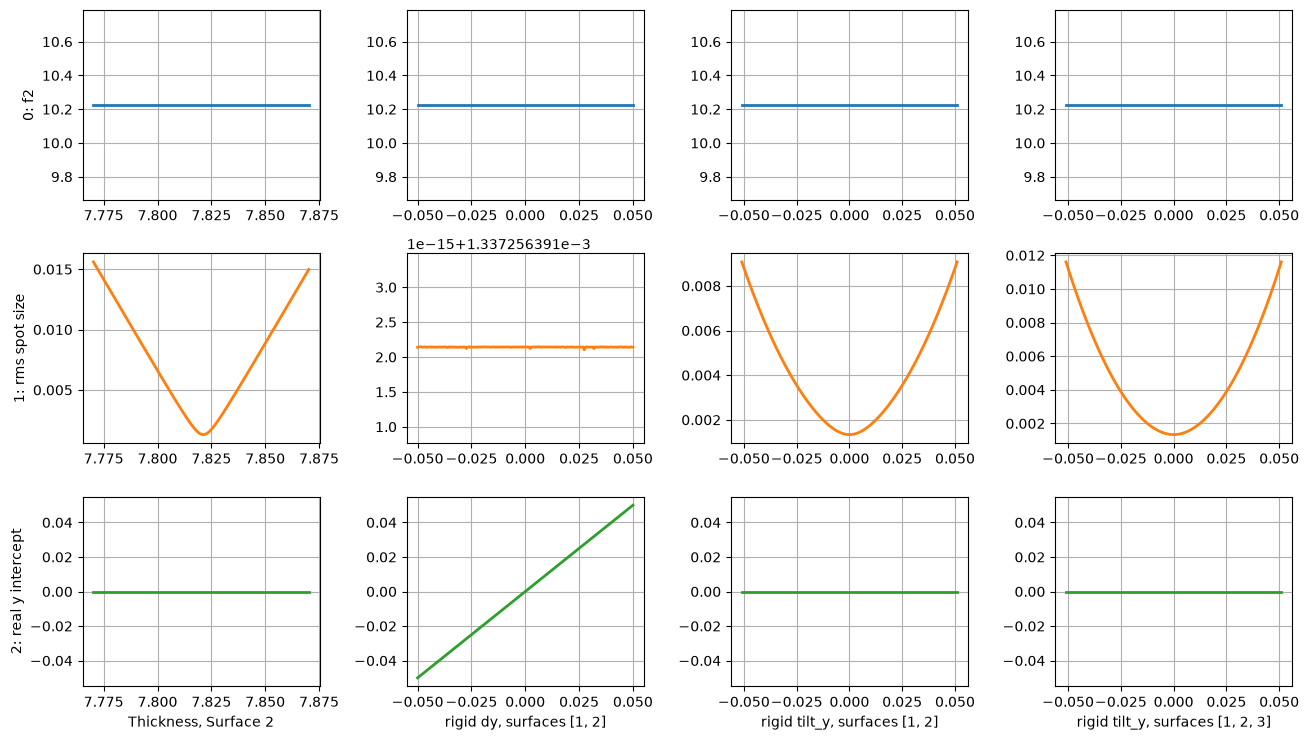

In [17]:
sensitivity_analysis.view(sharex="none", sharey="none")

In [18]:
import pandas as pd
from scipy.stats import linregress

# Linear fit of every operand (merit function contribution) against every tolerance sweep:
#     operand = slope * delta + intercept
# delta is the deviation from the centre of the sweep (the nominal value), so that the
# absolute-thickness sweep is comparable with the decenter/tilt sweeps (which are centred on 0).
df = sensitivity_analysis.get_results()

rows = []
for pert_type in df["perturbation_type"].unique():
    sub = df[df["perturbation_type"] == pert_type]
    x = np.asarray([float(v) for v in sub["perturbation_value"]])
    delta = x - 0.5 * (x.min() + x.max())
    for name in sensitivity_analysis.operand_names:
        y = np.asarray([float(v) for v in sub[name]])
        fit = linregress(delta, y)
        rows.append({
            "perturbation": pert_type,
            "operand": name,
            "nominal": 0.5 * (x.min() + x.max()),
            "range (+/-)": 0.5 * (x.max() - x.min()),
            "slope": fit.slope,
            "slope std err": fit.stderr,
            "intercept": fit.intercept,
            "intercept std err": fit.intercept_stderr,
            "R^2": fit.rvalue**2,
            "RMS residual": np.sqrt(np.mean((y - (fit.slope * delta + fit.intercept))**2)),
        })

fit_table = pd.DataFrame(rows).set_index(["perturbation", "operand"])

with pd.option_context("display.float_format", "{:.4e}".format, "display.width", 250,
                       "display.max_columns", None):
    print(fit_table)


                                                        nominal  range (+/-)       slope  slope std err  intercept  intercept std err        R^2  RMS residual
perturbation                     operand                                                                                                                      
Thickness, Surface 2             0: f2               7.8202e+00   5.0000e-02  0.0000e+00            NaN 1.0225e+01                NaN        NaN    0.0000e+00
                                 1: rms spot size    7.8202e+00   5.0000e-02 -9.2304e-03     1.0414e-02 7.8617e-03         3.0213e-04 3.9521e-03    4.2514e-03
                                 2: real y intercept 7.8202e+00   5.0000e-02  0.0000e+00            NaN 0.0000e+00                NaN        NaN    0.0000e+00
rigid dy, surfaces [1, 2]        0: f2               0.0000e+00   5.0000e-02  0.0000e+00            NaN 1.0225e+01                NaN        NaN    0.0000e+00
                                 1: rms spot s